# Predicting Credit Risk
## 1. Project Purpose
### Research Question
A bank that loans money to the wrong people can lose a lot of money. According to Shmueli et al. (Table 21.5), a good loan earns the bank 100 Deutsche Marks (DM) on average, while a bad loan costs 500 DM on average, which is five times as much. The purpose of this project is to analyze applicants' data to answer the following question: 

**Can we predict who will repay, so the bank approves the right people and loses less money?** 

### Goals
1. **Find the drivers:** identify which applicant traits are linked to bad credit
2. **Build a classifier:** train models that label new applicants as good or bad
3. **Maximize profit:** choose the model with the highest net profit

This report (Part 1) describes the dataset and begins to address goal 1 by exploring which applicants traits are linked to bad credit. It also prepares the data for modeling by checking for missing values, duplicates, and outliers, removing the ID column, and encoding categorical variables.

### Setup
Load the required libraries and the dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv('../data/GermanCredit.csv')

## 2. Describe the Data
### German Credit Dataset
This project uses the German Credit dataset as provided in Shmueli et al. (Chapter 21), adapted from the Statlog German Credit data in the UCI Machine Learning Repository. The origianl version is from the 20th century, when humans had to label records as either good or poor credit.
### Structure & Size
This dataset has 32 variables - 30 predictors, 1 target (RESPONSE), and one ID column (OBS#) - and 1,000 records. Each row is a prior applicant for credit. Each applicant was rated as "good credit", coded as 1, or "bad credit", coded as 0.

In [3]:
# number of columns and rows
data.shape

(1000, 32)

In [4]:
# first 5 records
data.head()

,OBS#,CHK_ACCT,DURATION,HISTORY,NEW_CAR,USED_CAR,FURNITURE,RADIO/TV,EDUCATION,RETRAINING,...,AGE,OTHER_INSTALL,RENT,OWN_RES,NUM_CREDITS,JOB,NUM_DEPENDENTS,TELEPHONE,FOREIGN,RESPONSE
0,1,0,6,4,0,0,0,1,0,0,...,67,0,0,1,2,2,1,1,0,1
1,2,1,48,2,0,0,0,1,0,0,...,22,0,0,1,1,2,1,0,0,0
2,3,3,12,4,0,0,0,0,1,0,...,49,0,0,1,1,1,2,0,0,1
3,4,0,42,2,0,0,1,0,0,0,...,45,0,0,0,1,2,2,0,0,1
4,5,0,24,3,1,0,0,0,0,0,...,53,0,0,0,2,2,2,0,0,0


### Target Variable

In [5]:
# target variable balance
counts = data['RESPONSE'].value_counts()
percentage = data['RESPONSE'].value_counts(normalize=True) * 100

pd.DataFrame({'Count' : counts, 'Percentage (%)' : percentage})

,Count,Percentage (%)
RESPONSE,,
1,700,70.0
0,300,30.0


Out of the 1,000 records, 700 (70%) were labeled as good credit and 300 (30%) as bad credit. This imbalance means accuracy can be misleading: a model that approved every applicant would be 70% accurate, yet the bank would lose 80,000 DM (700 × 100 − 300 × 500). Because of this imbalance, the data will also be split with stratification, so that both the training and validation sets keep the 70%/30% proportion.

### Variables

In [6]:
# columns' name, non-null count, and data type
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 32 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   OBS#              1000 non-null   int64
 1   CHK_ACCT          1000 non-null   int64
 2   DURATION          1000 non-null   int64
 3   HISTORY           1000 non-null   int64
 4   NEW_CAR           1000 non-null   int64
 5   USED_CAR          1000 non-null   int64
 6   FURNITURE         1000 non-null   int64
 7   RADIO/TV          1000 non-null   int64
 8   EDUCATION         1000 non-null   int64
 9   RETRAINING        1000 non-null   int64
 10  AMOUNT            1000 non-null   int64
 11  SAV_ACCT          1000 non-null   int64
 12  EMPLOYMENT        1000 non-null   int64
 13  INSTALL_RATE      1000 non-null   int64
 14  MALE_DIV          1000 non-null   int64
 15  MALE_SINGLE       1000 non-null   int64
 16  MALE_MAR_or_WID   1000 non-null   int64
 17  CO-APPLICANT      1000 non-null   int64
 18  

In [7]:
# number of unique values per column
data.nunique()

OBS#                1000
CHK_ACCT               4
DURATION              33
HISTORY                5
NEW_CAR                2
USED_CAR               2
FURNITURE              2
RADIO/TV               2
EDUCATION              2
RETRAINING             2
AMOUNT               921
SAV_ACCT               5
EMPLOYMENT             5
INSTALL_RATE           4
MALE_DIV               2
MALE_SINGLE            2
MALE_MAR_or_WID        2
CO-APPLICANT           2
GUARANTOR              2
PRESENT_RESIDENT       4
REAL_ESTATE            2
PROP_UNKN_NONE         2
AGE                   53
OTHER_INSTALL          2
RENT                   2
OWN_RES                2
NUM_CREDITS            4
JOB                    4
NUM_DEPENDENTS         2
TELEPHONE              2
FOREIGN                2
RESPONSE               2
dtype: int64

All columns are stored as integers, but they represent four different types of variables (Table 21.3):

- **Binary (0/1):** NEW_CAR, USED_CAR, FURNITURE, RADIO/TV, EDUCATION, RETRAINING, MALE_DIV, MALE_SINGLE, MALE_MAR_or_WID, CO-APPLICANT, GUARANTOR, REAL_ESTATE, PROP_UNKN_NONE, OTHER_INSTALL, RENT, OWN_RES, TELEPHONE, FOREIGN. These are used as they are.
- **Categorical codes:** CHK_ACCT, HISTORY, SAV_ACCT, JOB. The codes are labels, not amounts, so these will be one-hot encoded.
- **Ordered codes:** EMPLOYMENT, PRESENT_RESIDENT, INSTALL_RATE. Higher codes mean more, so these are treated as numbers.
- **Numeric:** AMOUNT, DURATION, AGE, NUM_CREDITS, NUM_DEPENDENTS. These are used as they are.

Together, these make up the 30 predictors.

### Summary Statistics

In [8]:
# summary statistics
numeric_cols = ['AMOUNT', 'DURATION', 'AGE']
data[numeric_cols].describe().round(2)

,AMOUNT,DURATION,AGE
count,1000.00,1000.00,1000.00
mean,3271.26,20.90,35.55
std,2822.74,12.06,11.38
min,250.00,4.00,19.00
25%,1365.50,12.00,27.00
50%,2319.50,18.00,33.00
75%,3972.25,24.00,42.00
max,18424.00,72.00,75.00


The typical loan is 2,320 DM over 18 months, and the typical applicant is 33 years old (medians). All three variables are right-skewed: the mean is higher than the median in each case, most clearly for AMOUNT, where the mean (3,271 DM) is about 950 DM above the median. The maximums are also far above the 75th percentiles: a loan of 18,424 DM compared with 3,972 DM, a duration of 72 months compared with 24, and an age of 75 compared with 42. This suggests a few unusually large loans, long durations, and older applicants. Section 3 checks whether these are outliers using box plots.

I check the distribution of foreign workers, a sensitive variable discussed in the biases below.

In [9]:
# foreign worker distribution (1 = yes, 0 = no)
data['FOREIGN'].value_counts()

FOREIGN
0    963
1     37
Name: count, dtype: int64

### Assumptions, Limitations, and Biases

**Assumptions**

- **Labels are accurate:** RESPONSE was assigned based on a person's judgment, and the analysis assumes the ratings are correct. If they contain errors, the models will learn and repeat them.
- **Profit values are fixed:** the +100 DM and −500 DM figures are averages, but the analysis applies them to every loan, even though real gains and losses depend on the loan amount.
- **Codes are meaningful:** ordered variables such as EMPLOYMENT and INSTALL_RATE are treated as numbers, which assumes each step between codes represents a real increase.

**Limitations**

- **Old and local data:** the records come from a single German bank, collected awhile ago and recorded in Deutsche Marks, so the patterns may not apply to today's borrowers or to other countries.
- **Small sample:** with only 1,000 applicants, and 300 bad ones, complex models such as neural networks may overfit.
- **Imbalanced classes:** as shown above, 70% of applicants are good credit, so accuracy alone is a misleading measure of model performance.

**Biases**

- **Gender coding:** sex and marital status are combined into three variables for men only (MALE_DIV, MALE_SINGLE, MALE_MAR_or_WID). Women have no category of their own, so the data separates men by marital status but records no marital information for women.
- **Foreign workers:** according to Table 21.3, FOREIGN = 1 indicates a foreign worker, and only a small share of applicants fall into that group. The models will therefore learn little about foreign workers, and using this variable in lending decisions raises fairness concerns.
- **Age:** AGE may be a strong predictor, but rejecting applicants because they are young or old is a fairness concern.
- **Human judgment:** because the labels come from human raters, any bias in how they judged certain groups is built into the data.

In real lending, decisions based on sex, marital status, age, or national origin are restricted by fair-lending laws, so these variables require careful interpretation.


## 3. Clean, Prepare and Visualize the Data
In this section, I check the quality of the data, look for outliers, and explore which applicant traits are linked to bad credit. Then I create new variables, encode the categorical variables, and split the data into training and validation sets so it is ready for modeling.

### Missing Values
I check if any column has missing values.

In [10]:
# total number of missing values in the dataset
data.isnull().sum().sum()

np.int64(0)

There are no missing values in any of the 32 columns, which matches the data.info() output in Section 2 (1,000 non-null values per column). No imputation or row removal is needed.

### Duplicates
I check for duplicate rows. OBS# is left out of this check, because every row has a different ID, so duplicates would never be found if it were included.

In [11]:
# number of duplicate rows, ignoring the ID column
data.drop(columns='OBS#').duplicated().sum()

np.int64(0)

There are no duplicate records, so every row represents a different applicant and nothing needs to be removed.

### Valid Codes
Since most columns are codes, a wrong value (for example, a 2 in a binary column) would not show up as a missing value. I check that the binary columns only contain 0 and 1, and look at the range of each coded column.

In [12]:
# binary columns should only contain 0 and 1
binary_cols = ['NEW_CAR', 'USED_CAR', 'FURNITURE', 'RADIO/TV', 'EDUCATION', 'RETRAINING',
               'MALE_DIV', 'MALE_SINGLE', 'MALE_MAR_or_WID', 'CO-APPLICANT', 'GUARANTOR',
               'REAL_ESTATE', 'PROP_UNKN_NONE', 'OTHER_INSTALL', 'RENT', 'OWN_RES',
               'TELEPHONE', 'FOREIGN', 'RESPONSE']

data[binary_cols].isin([0, 1]).all().all()

np.True_

In [13]:
# minimum and maximum of each coded column
coded_cols = ['CHK_ACCT', 'HISTORY', 'SAV_ACCT', 'JOB', 'EMPLOYMENT', 'PRESENT_RESIDENT', 'INSTALL_RATE']

data[coded_cols].agg(['min', 'max'])

,CHK_ACCT,HISTORY,SAV_ACCT,JOB,EMPLOYMENT,PRESENT_RESIDENT,INSTALL_RATE
min,0,0,0,0,0,1,1
max,3,4,4,3,4,4,4


All binary columns contain only 0 and 1. The coded columns are whole numbers within small ranges (for example, CHK_ACCT goes from 0 to 3 and HISTORY from 0 to 4), which match the categories described in Table 21.3. There are no invalid codes to fix.

### Outliers
In Section 2, the summary statistics showed that AMOUNT, DURATION, and AGE have maximums far above their 75th percentiles. I use box plots to check these variables for outliers.

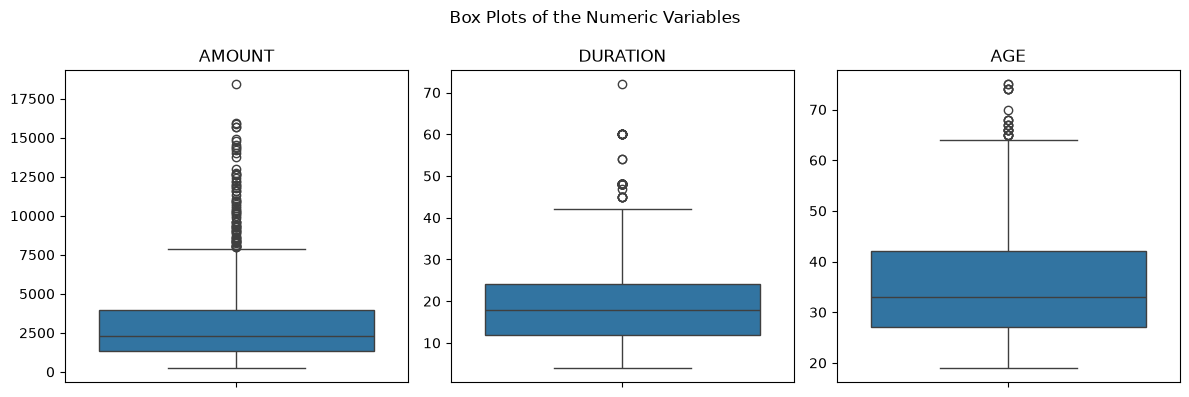

In [14]:
# box plots of the numeric variables
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=data[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')

plt.suptitle('Box Plots of the Numeric Variables')
plt.tight_layout()
plt.show()

The box plots show points above the upper whisker for all three variables. To count them, I use the same rule the box plot uses: a value is an outlier if it is more than 1.5 times the interquartile range (IQR) above the 75th percentile or below the 25th percentile.

In [15]:
# count outliers with the 1.5 x IQR rule
for col in numeric_cols:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr
    n_outliers = ((data[col] > upper) | (data[col] < lower)).sum()
    print(f'{col}: {n_outliers} outliers (upper limit = {upper:,.1f})')

AMOUNT: 72 outliers (upper limit = 7,882.4)
DURATION: 70 outliers (upper limit = 42.0)
AGE: 23 outliers (upper limit = 64.5)


There are 72 outliers in AMOUNT (loans above about 7,882 DM), 70 in DURATION (loans longer than 42 months), and 23 in AGE (applicants older than 64). There are no outliers on the low side.

Before deciding what to do with them, I check if these applicants are different in terms of credit risk.

In [16]:
# percentage of bad credit for outlier loans vs. the rest
for col in ['AMOUNT', 'DURATION']:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    is_outlier = data[col] > upper
    bad_outliers = (data.loc[is_outlier, 'RESPONSE'] == 0).mean() * 100
    bad_others = (data.loc[~is_outlier, 'RESPONSE'] == 0).mean() * 100
    print(f'{col}: {bad_outliers:.1f}% bad among outliers vs. {bad_others:.1f}% for the rest')

AMOUNT: 54.2% bad among outliers vs. 28.1% for the rest
DURATION: 57.1% bad among outliers vs. 28.0% for the rest


**Decision: I keep all outliers.** These are not data entry errors: a loan of 18,424 DM, a 72-month loan, or a 75-year-old applicant are all realistic values. More importantly, the outliers carry useful information. More than half of the very large loans (54.2%) and very long loans (57.1%) were bad credit, compared with about 28% for the rest. Removing them would delete exactly the risky applicants the bank needs to identify, and would also remove 138 rows (13.8% of a small dataset). As the textbook suggests, the decision is based on domain knowledge: outliers should be removed when they are likely errors, not just because they are extreme.

### Removing the ID Column
OBS# only numbers the rows and does not describe the applicant, so it cannot help predict credit risk. I remove it.

In [17]:
# drop the ID column
data = data.drop(columns='OBS#')
data.shape

(1000, 31)

The dataset now has 31 columns: 30 predictors and the target.

### Creating New Variables
I create two new variables:

- **MONTHLY_PAYMENT** (a ratio): AMOUNT divided by DURATION, which gives the approximate amount the applicant pays per month (ignoring interest). Two loans of the same amount can be very different if one has to be paid in 6 months and the other in 48 months.
- **AGE_GROUP** (a category): AGE grouped into ranges, to make it easier to compare credit risk across ages in a chart.

In [18]:
# new ratio variable: approximate payment per month
data['MONTHLY_PAYMENT'] = (data['AMOUNT'] / data['DURATION']).round(2)

# new category variable: age ranges
data['AGE_GROUP'] = pd.cut(data['AGE'], bins=[18, 25, 35, 50, 75],
                           labels=['19-25', '26-35', '36-50', '51-75'])

data[['AMOUNT', 'DURATION', 'MONTHLY_PAYMENT', 'AGE', 'AGE_GROUP']].head()

,AMOUNT,DURATION,MONTHLY_PAYMENT,AGE,AGE_GROUP
0,1169,6,194.83,67,51-75
1,5951,48,123.98,22,19-25
2,2096,12,174.67,49,36-50
3,7882,42,187.67,45,36-50
4,4870,24,202.92,53,51-75


In [19]:
# summary of the new ratio variable
data['MONTHLY_PAYMENT'].describe().round(1)

count    1000.0
mean      167.7
std       153.5
min        24.1
25%        89.6
50%       130.3
75%       206.2
max      2482.7
Name: MONTHLY_PAYMENT, dtype: float64

The median monthly payment is about 130 DM, and most applicants pay between 90 and 206 DM per month. AGE_GROUP is only used for exploring the data in the next step. It is not used for modeling, because AGE already contains the same information in more detail.

### Exploring Which Traits Are Linked to Bad Credit
This step begins to address goal 1. For several variables, I calculate the percentage of applicants in each group who were rated bad credit, and compare it with the overall rate of 30%. The category labels come from Table 21.3.

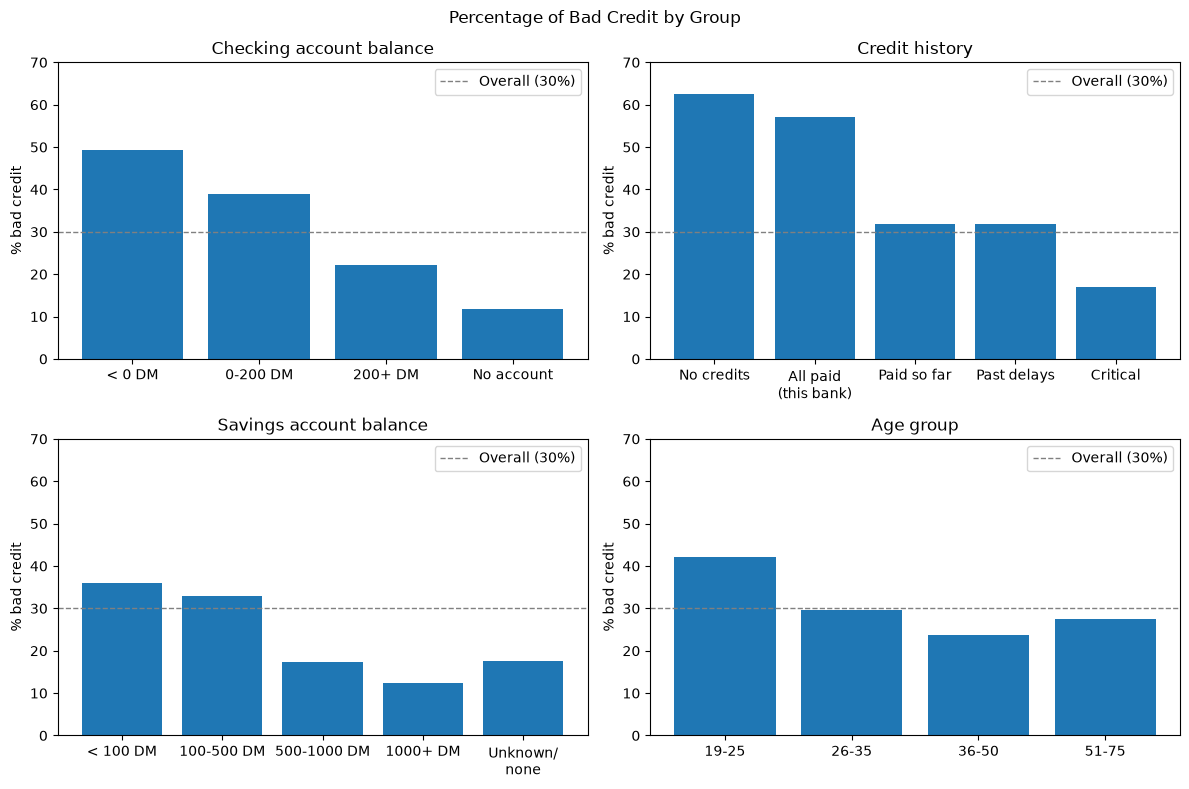

In [20]:
# percentage of bad credit in each group of a variable
def bad_rate(col):
    return (data['RESPONSE'] == 0).groupby(data[col], observed=True).mean() * 100

charts = {
    'CHK_ACCT': ['< 0 DM', '0-200 DM', '200+ DM', 'No account'],
    'HISTORY': ['No credits', 'All paid\n(this bank)', 'Paid so far', 'Past delays', 'Critical'],
    'SAV_ACCT': ['< 100 DM', '100-500 DM', '500-1000 DM', '1000+ DM', 'Unknown/\nnone'],
    'AGE_GROUP': ['19-25', '26-35', '36-50', '51-75'],
}
titles = {
    'CHK_ACCT': 'Checking account balance',
    'HISTORY': 'Credit history',
    'SAV_ACCT': 'Savings account balance',
    'AGE_GROUP': 'Age group',
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (col, labels) in zip(axes.flatten(), charts.items()):
    rates = bad_rate(col)
    ax.bar(labels, rates.values)
    ax.axhline(30, color='gray', linestyle='--', linewidth=1, label='Overall (30%)')
    ax.set_title(titles[col])
    ax.set_ylabel('% bad credit')
    ax.set_ylim(0, 70)
    ax.legend()

plt.suptitle('Percentage of Bad Credit by Group')
plt.tight_layout()
plt.show()

Some variables show large differences between groups:

- **Checking account:** applicants with a negative balance (< 0 DM) were bad credit 49.3% of the time, while applicants with no checking account were bad credit only 11.7% of the time. This is the strongest difference in the charts.
- **Credit history:** applicants with no credits taken (62.5%) or with all credits at this bank paid back (57.1%) had the highest bad credit rates. Surprisingly, the "critical account" group had the lowest rate (17.1%). One possible explanation is that the bank was already more careful when approving loans for these applicants, so only the safer ones were in the data.
- **Savings:** applicants with less than 100 DM in savings had a higher bad credit rate (36.0%) than applicants with 1,000 DM or more (12.5%).
- **Age:** the youngest group (19-25) had the highest bad credit rate (42.1%), compared with 23.7% for ages 36-50. This makes age a likely driver, but, as discussed in Section 2, using it to reject applicants raises fairness concerns.

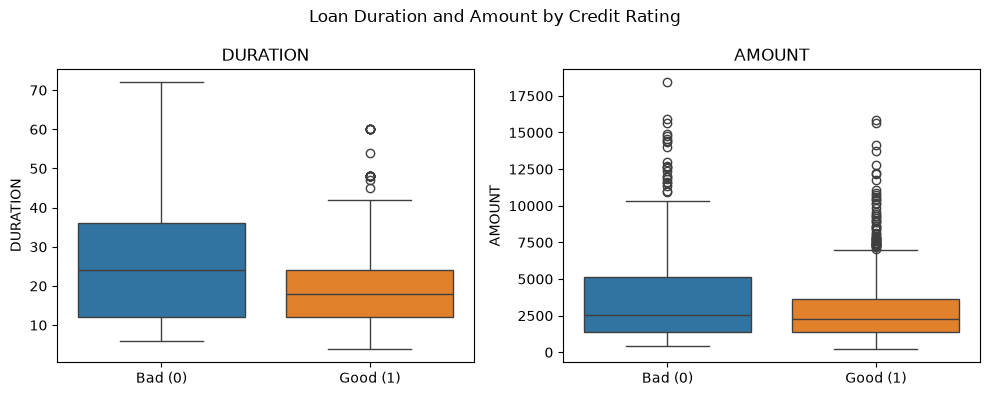

In [21]:
# compare loan duration and amount for good vs. bad credit
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ['DURATION', 'AMOUNT']):
    sns.boxplot(data=data, x='RESPONSE', y=col, ax=ax,
                hue='RESPONSE', legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Bad (0)', 'Good (1)'])
    ax.set_xlabel('')
    ax.set_title(col)

plt.suptitle('Loan Duration and Amount by Credit Rating')
plt.tight_layout()
plt.show()

In [22]:
# medians for good vs. bad credit
data.groupby('RESPONSE')[['DURATION', 'AMOUNT', 'MONTHLY_PAYMENT', 'AGE']].median()

,DURATION,AMOUNT,MONTHLY_PAYMENT,AGE
RESPONSE,,,,
0,24.0,2574.5,121.060,31.0
1,18.0,2244.0,134.915,34.0


Bad credit applicants tend to have longer loans (median of 24 months vs. 18 months) and slightly larger loans (2,574.5 DM vs. 2,244 DM). The new MONTHLY_PAYMENT variable shows the opposite of what I expected: bad credit applicants have a slightly *lower* median monthly payment (121 DM vs. 135 DM). This is because their loans are spread over more months, which suggests that loan duration matters more than the size of the monthly payment.

Overall, checking account status, credit history, savings, loan duration, and age look like the most promising drivers of bad credit. The models in Part 2 will test which of these are actually useful for prediction.

### Encoding Categorical Variables
CHK_ACCT, HISTORY, SAV_ACCT, and JOB are categorical codes: the numbers are labels, not amounts (for example, CHK_ACCT = 3 means "no checking account," which is not "more" than CHK_ACCT = 2). If they were used as numbers, a model would treat them as ordered. I convert them into dummy (0/1) variables with one-hot encoding.

Following the textbook, I use drop_first=True, which removes one dummy per variable. The dropped category becomes the reference group, and this avoids redundant columns in models such as logistic regression. I also remove AGE_GROUP, since it was only created for exploration.

In [23]:
# one-hot encode the categorical codes
categorical_cols = ['CHK_ACCT', 'HISTORY', 'SAV_ACCT', 'JOB']

model_data = data.drop(columns='AGE_GROUP')
model_data = pd.get_dummies(model_data, columns=categorical_cols, drop_first=True, dtype=int)

model_data.shape

(1000, 42)

In [24]:
# new dummy columns
[col for col in model_data.columns if col.startswith(tuple(categorical_cols))]

['CHK_ACCT_1',
 'CHK_ACCT_2',
 'CHK_ACCT_3',
 'HISTORY_1',
 'HISTORY_2',
 'HISTORY_3',
 'HISTORY_4',
 'SAV_ACCT_1',
 'SAV_ACCT_2',
 'SAV_ACCT_3',
 'SAV_ACCT_4',
 'JOB_1',
 'JOB_2',
 'JOB_3']

The 4 categorical columns were replaced by 14 dummy variables, so the data now has 42 columns: 41 predictors (including MONTHLY_PAYMENT) and the target.

### Partitioning the Data
As explained in Section 2, I split the data into a training set (60%) and a validation set (40%), stratified on RESPONSE so both sets keep the 70/30 proportion. The training set will be used to build the models, and the validation set to compare them on data they have not seen. I use `random_state=1` so the split is the same every time the notebook runs.

In [25]:
# separate predictors (X) and target (y)
X = model_data.drop(columns='RESPONSE')
y = model_data['RESPONSE']

# 60% training, 40% validation, stratified on the target
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.4, random_state=1, stratify=y)

print('Training set:', X_train.shape)
print('Validation set:', X_valid.shape)
print(f'Good credit in training: {y_train.mean() * 100:.1f}%')
print(f'Good credit in validation: {y_valid.mean() * 100:.1f}%')

Training set: (600, 41)
Validation set: (400, 41)
Good credit in training: 70.0%
Good credit in validation: 70.0%


The training set has 600 applicants and the validation set has 400. Both keep exactly 70% good credit, so the split worked as planned.

### Summary of Part 1
- The data has no missing values, no duplicates, and no invalid codes.
- AMOUNT, DURATION, and AGE have outliers, but they are realistic values and are linked to a higher rate of bad credit, so they were kept.
- OBS# was removed, and two new variables were created: MONTHLY_PAYMENT (ratio) and AGE_GROUP (category, for exploration only).
- Checking account status, credit history, savings, loan duration, and age show the largest differences in bad credit rates, which gives a first answer to goal 1.
- The categorical variables were one-hot encoded, and the data was split 60/40 with stratification, so it is ready for the models in Part 2.

## References
- Shmueli, G., Bruce, P. C., Gedeck, P., & Patel, N. R. *Data Mining for Business Analytics: Concepts, Techniques, and Applications in Python*. Wiley. Chapter 21: German Credit case.
- Hofmann, H. (1994). Statlog (German Credit Data). UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/144